# Phase 1 - one shared input format (laptop version)

Runs on the laptop, straight from `D:/wifi/Datasets` - no Colab, no Google Drive, no uploads.

| Step | What happens |
|---|---|
| 20 MHz slice | 80 MHz data is cut into its four 20 MHz sub-bands, **52 tones each** (WiCount already has 52) |
| One link | Every antenna x sub-band is stored as a separate **view** (one view = what one ESP32 would see) |
| Amplitude only | Phase is dropped |
| Gain normalisation | Each packet is divided by its median over tones (removes automatic gain jumps) |
| 50 Hz grid | Packets are averaged into 20 ms bins; gaps up to 60 ms are interpolated, longer gaps stay **missing** |
| Recording normalisation | Each tone is divided by its mean over the recording (per receiver) -> relative fluctuation |
| Windows | 5 s windows, 2.5 s hop; windows with > 20 % missing bins are dropped |
| Count cues | 10 features per window and view (fluctuation, motion energy, number of independent patterns, ...) |

```
D:/wifi/Datasets/Dataset/PC-1a ... PC-4a/*.mat             (80 MHz set, 5.6 GB)
D:/wifi/Datasets/CountFi/48/48_<rx>_<scenario>/<count>/*.pcap   (4.9 GB)
D:/wifi/Datasets/WiCount/data/<count>/*.csv                (41 MB)
```

**Needs:** `numpy pandas pyarrow matplotlib` (CPU only - this phase does not use the GPU).

Output: `D:/wifi/shared_format/<dataset>/<recording>.npz` + `features.parquet`.
The run is resumable: recordings already saved are skipped, so you can stop and restart any time.

In [1]:
# 1. Paths and settings (laptop)
import glob
import json
import os
import shutil
import struct
import time
import zlib
from pathlib import Path

import numpy as np
import pandas as pd

WIFI_ROOT = "D:/wifi"
RAW = f"{WIFI_ROOT}/Datasets"                   # the three dataset folders
OUT_ROOT = f"{WIFI_ROOT}/shared_format"         # Phase 1 output

SOURCES = {
    "mat80": "Dataset",
    "countfi": "CountFi",
    "wicount": "WiCount",
}

# ---- shared-format settings (keep identical on the ESP32 later) ----
FS = 50              # common sample rate (Hz)
WIN_S = 5.0          # window length (s)
HOP_S = 2.5          # window hop (s)
MAX_GAP_BINS = 3     # gaps up to 3 bins (60 ms) are interpolated
MAX_MISSING = 0.20   # drop windows with more missing bins than this
N_TONES = 52

# ---- Check the data is really there before processing ----
counts = {
    "mat80": len(glob.glob(os.path.join(RAW, "Dataset", "PC-*", "*.mat"))),
    "countfi": len(glob.glob(os.path.join(RAW, "CountFi", "**", "*.pcap"), recursive=True)),
    "wicount": len(glob.glob(os.path.join(RAW, "WiCount", "data", "*", "*.csv"))),
}
for key, n in counts.items():
    print(f"{key:8s} {os.path.join(RAW, SOURCES[key]):35s} {n:6d} files")

empty = [key for key, n in counts.items() if n == 0]
if empty:
    raise FileNotFoundError(f"No data files found for {empty} under {RAW}. Check the folder names.")

os.makedirs(OUT_ROOT, exist_ok=True)
free_gb = shutil.disk_usage(WIFI_ROOT).free / 1e9
print(f"output: {OUT_ROOT}   free on D: {free_gb:.1f} GB")

mat80    D:/wifi/Datasets\Dataset                40 files
countfi  D:/wifi/Datasets\CountFi              4754 files
wicount  D:/wifi/Datasets\WiCount                15 files
output: D:/wifi/shared_format   free on D: 28.4 GB


In [2]:
# 3. Shared-format helpers: sub-bands, 50 Hz grid, normalisation, count cues

# ---------------------------------------------------------------
# 20 MHz sub-bands of an 80 MHz channel (256-point FFT, natural order)
# ---------------------------------------------------------------
# Sub-band s covers tone indices -128+64s ... -65+64s. We keep 52 tones,
# skipping 6 at each edge. This automatically avoids DC (bins 0, 1, 255)
# and the guard band (bins 123-133) that carry no channel data.
def subband_bins(s):
    start = -128 + 64 * s
    tones = np.arange(start + 6, start + 6 + N_TONES)
    return np.mod(tones, 256)


SUBBANDS = [subband_bins(s) for s in range(4)]


# ---------------------------------------------------------------
# Normalisation
# ---------------------------------------------------------------
def gain_normalise(A):
    """Per packet: divide by the median over tones (removes AGC jumps)."""
    return A / (np.median(A, axis=1, keepdims=True) + 1e-6)


def recording_normalise(X):
    """Per recording + receiver: each tone relative to its mean -> fluctuation around 0."""
    mu = np.nanmean(X, axis=0, keepdims=True)
    dead = mu < 1e-3 * np.nanmedian(mu)                    # null tones, if any
    Y = X / (mu + 1e-6) - 1.0
    Y[:, dead[0]] = 0.0
    return Y


# ---------------------------------------------------------------
# Resampling onto the 50 Hz grid
# ---------------------------------------------------------------
def resample_to_grid(t, A):
    """t: packet times (s, sorted), A: (packets, tones).
    Returns X (bins, tones) with NaN rows for empty bins, and the valid mask."""
    idx = np.floor((t - t[0]) * FS).astype(np.int64)
    n_bins = int(idx[-1]) + 1

    uniq, first = np.unique(idx, return_index=True)        # idx is sorted
    sums = np.add.reduceat(A.astype(np.float64), first, axis=0)
    counts = np.diff(np.append(first, len(idx)))

    X = np.full((n_bins, A.shape[1]), np.nan, dtype=np.float32)
    X[uniq] = sums / counts[:, None]
    valid = np.zeros(n_bins, dtype=bool)
    valid[uniq] = True
    return X, valid


def fill_short_gaps(X, valid):
    """Linear interpolation over gaps of at most MAX_GAP_BINS; longer gaps stay NaN."""
    X, valid = X.copy(), valid.copy()
    missing = np.flatnonzero(~valid)
    if len(missing) == 0:
        return X, valid

    runs = np.split(missing, np.flatnonzero(np.diff(missing) > 1) + 1)
    for run in runs:
        left, right = run[0] - 1, run[-1] + 1
        if len(run) <= MAX_GAP_BINS and left >= 0 and right < len(X):
            w = ((run - left) / (right - left))[:, None]
            X[run] = X[left] * (1 - w) + X[right] * w
            valid[run] = True
    return X, valid


def to_shared_series(t, A):
    """Raw amplitude of ONE view -> normalised 50 Hz series (bins, 52) + valid mask."""
    A = gain_normalise(A.astype(np.float32))
    X, valid = resample_to_grid(t, A)
    X, valid = fill_short_gaps(X, valid)
    return recording_normalise(X), valid


# ---------------------------------------------------------------
# Count cues per window
# ---------------------------------------------------------------
FEATURE_NAMES = [
    "cv_median",       # median over tones of the fluctuation std
    "cv_p90",          # 90th percentile of the same
    "cv_p10",          # 10th percentile of the same
    "diff_energy",     # mean |x(t) - x(t-1)|  (motion energy)
    "pc1_frac",        # share of variance in the first principal component
    "n_pc_90",         # components needed for 90 % of the variance
    "tone_corr",       # mean correlation between tones
    "low_freq_frac",   # temporal power below 2 Hz (slow body motion)
    "high_freq_frac",  # temporal power above 5 Hz
    "mean_std",        # std of the tone-averaged series
]


def window_features(W):
    """W: (bins, 52) normalised window. Missing bins count as 'no change' (0)."""
    W = np.nan_to_num(W.astype(np.float32))
    sd = W.std(axis=0)
    diff_energy = np.abs(np.diff(W, axis=0)).mean()

    Xc = W - W.mean(axis=0)
    s = np.linalg.svd(Xc, compute_uv=False) ** 2
    frac = s / (s.sum() + 1e-12)
    n90 = np.searchsorted(np.cumsum(frac), 0.90) + 1

    with np.errstate(invalid="ignore", divide="ignore"):
        C = np.corrcoef(Xc.T)
    tone_corr = np.nanmean(C[np.triu_indices_from(C, k=1)])

    x = Xc.mean(axis=1)
    P = np.abs(np.fft.rfft(x)) ** 2
    f = np.fft.rfftfreq(len(x), 1.0 / FS)
    p_total = P[f > 0].sum() + 1e-12
    low = P[(f > 0) & (f < 2.0)].sum() / p_total
    high = P[f > 5.0].sum() / p_total

    return np.array([np.median(sd), np.percentile(sd, 90), np.percentile(sd, 10),
                     diff_energy, frac[0], n90, tone_corr, low, high, x.std()],
                    dtype=np.float32)


# ---------------------------------------------------------------
# Windowing + saving one recording
# ---------------------------------------------------------------
def save_recording(rec):
    """rec: dict with series (views, bins, 52), valid (bins,), view_names, metadata."""
    S, valid = rec["series"], rec["valid"]
    win, hop = int(WIN_S * FS), int(HOP_S * FS)

    starts = [a for a in range(0, S.shape[1] - win + 1, hop)
              if valid[a:a + win].mean() >= 1 - MAX_MISSING]

    F = np.zeros((S.shape[0], len(starts), len(FEATURE_NAMES)), dtype=np.float32)
    for v in range(S.shape[0]):
        for j, a in enumerate(starts):
            F[v, j] = window_features(S[v, a:a + win])

    meta = {k: rec[k] for k in ["dataset", "recording", "group", "setup", "receiver", "count"]}
    meta["seconds"] = round(S.shape[1] / FS, 1)
    meta["missing_frac"] = round(float(1 - valid.mean()), 4)
    meta["n_windows"] = len(starts)

    out_dir = os.path.join(OUT_ROOT, rec["dataset"])
    os.makedirs(out_dir, exist_ok=True)
    np.savez_compressed(os.path.join(out_dir, rec["recording"] + ".npz"),
                        series=S.astype(np.float16), valid=valid,
                        starts=np.array(starts, dtype=np.int32), feats=F,
                        view_names=np.array(rec["view_names"]), meta=json.dumps(meta))
    return meta


def already_done(dataset, recording):
    return os.path.exists(os.path.join(OUT_ROOT, dataset, recording + ".npz"))


print("sub-band bins:", [(int(b[0]), int(b[-1])) for b in SUBBANDS])

sub-band bins: [(134, 185), (198, 249), (6, 57), (70, 121)]


In [3]:
# 4. 80 MHz set (Dataset/PC-*a/*.mat): 4 antennas x 4 sub-bands = 16 views per recording
MAT80_RATE = 173          # packets/s per antenna (published; the files have no timestamps)
MI_TYPES = {1: "i1", 2: "u1", 3: "<i2", 4: "<u2", 5: "<i4", 6: "<u4", 7: "<f4", 9: "<f8"}


# ---------------------------------------------------------------
# Streaming MAT-v5 reader (column by column, low RAM)
# ---------------------------------------------------------------
class ZStream:
    def __init__(self, f, comp_len):
        self.f, self.left = f, comp_len
        self.d, self.buf = zlib.decompressobj(), bytearray()

    def read(self, n):
        while len(self.buf) < n:
            if self.left <= 0:
                self.buf += self.d.flush()
                break
            chunk = self.f.read(min(4 << 20, self.left))
            self.left -= len(chunk)
            self.buf += self.d.decompress(chunk)
        out = bytes(self.buf[:n])
        del self.buf[:n]
        return out


def read_tag(src):
    raw = src.read(8)
    t, n = struct.unpack("<II", raw)
    if t >> 16:                                   # small data element
        return t & 0xFFFF, t >> 16, raw[4:4 + (t >> 16)], True
    return t, n, None, False


def read_element(src):
    t, n, small, is_small = read_tag(src)
    if is_small:
        return t, small
    data = src.read(n)
    if n % 8:
        src.read(8 - n % 8)
    return t, data


def load_amplitude(path):
    """Return amplitude (rows, 256) float16, or None if the file holds no data."""
    with open(path, "rb") as f:
        f.read(128)
        _, n = struct.unpack("<II", f.read(8))
        src = ZStream(f, n)
        read_tag(src)                             # miMATRIX
        read_element(src)                         # flags
        _, dims = read_element(src)
        nrows, ncols = struct.unpack("<ii", dims[:8])
        read_element(src)                         # variable name
        if nrows == 0:
            return None

        t, nbytes, _, _ = read_tag(src)           # real part
        dt = np.dtype(MI_TYPES[t])
        R = np.empty((nrows, ncols), dtype=np.int16)
        for c in range(ncols):
            R[:, c] = np.frombuffer(src.read(nrows * dt.itemsize), dtype=dt)
        if nbytes % 8:
            src.read(8 - nbytes % 8)

        t, nbytes, _, _ = read_tag(src)           # imaginary part -> amplitude
        dt = np.dtype(MI_TYPES[t])
        A = np.empty((nrows, ncols), dtype=np.float16)
        for c in range(ncols):
            im = np.frombuffer(src.read(nrows * dt.itemsize), dtype=dt).astype(np.float32)
            A[:, c] = np.hypot(R[:, c].astype(np.float32), im)
    return A


def process_mat80(path):
    name = Path(path).stem                         # PC1a_n02
    setup = name.split("_")[0]
    count = int(name.split("_n")[1])
    try:
        A = load_amplitude(path)
    except struct.error:                           # header only, no data stream
        A = None
    if A is None:
        return None

    n = (len(A) // 4) * 4                          # rows cycle over the 4 antennas
    series, views, valid_all = [], [], None
    for ant in range(4):
        A_ant = A[ant:n:4]
        t = np.arange(len(A_ant)) / MAT80_RATE
        for s, bins in enumerate(SUBBANDS):
            X, valid = to_shared_series(t, A_ant[:, bins])
            series.append(X)
            views.append(f"ant{ant}_sb{s}")
            valid_all = valid if valid_all is None else (valid_all & valid)

    return dict(dataset="mat80", recording=name, group=setup, setup=setup, receiver="rx",
                count=count, series=np.stack(series), valid=valid_all, view_names=views)


mat_files = sorted(glob.glob(os.path.join(RAW, "Dataset", "PC-*", "*.mat")))
print(len(mat_files), "MAT files")
t0 = time.time()
for path in mat_files:
    name = Path(path).stem
    if already_done("mat80", name):
        continue
    rec = process_mat80(path)
    if rec is None:
        print(f"{name:12s} EMPTY - skipped")
        continue
    meta = save_recording(rec)
    print(f"{name:12s} count={meta['count']:2d}  {meta['seconds']:6.1f} s  "
          f"windows={meta['n_windows']:3d}  missing={meta['missing_frac']:.3f}  "
          f"[{time.time() - t0:.0f} s]")

40 MAT files
PC2a_n00     EMPTY - skipped


In [4]:
# 5. CountFi (CountFi/48/48_<rx>_<scenario>/<count>/*.pcap): QoS-data frames only, 4 sub-bands
# One recording = one (scenario, receiver, count) block.
# Each .pcap is a ~1 s burst (1000 packets) followed by ~1.2 s of nothing before the next file,
# so on real time only ~40 % of the 50 Hz bins would have data and every 5 s window would be dropped.
# The bursts are therefore STITCHED back to back (dead time between files removed).
# Split unit later = scenario (head and end of the same scenario always stay together).
ETH, IP, UDP, NEX = 14, 20, 8, 18


def read_qos(path):
    """Return (times s, amplitude (packets, 256)) of the QoS-data frames, or None."""
    data = open(path, "rb").read()
    off, ts, payloads = 24, [], []
    while off + 16 <= len(data):
        sec, usec, incl, _ = struct.unpack_from("<IIII", data, off)
        off += 16
        pkt = data[off:off + incl]
        off += incl
        p = pkt[ETH + IP + UDP:]
        if p[:2] != b"\x11\x11" or len(p) != NEX + 1024 or p[3] != 0x88:
            continue                               # not a Nexmon QoS-data CSI frame
        ts.append(sec + usec * 1e-6)
        payloads.append(p[NEX:])
    if not payloads:
        return None
    raw = np.frombuffer(b"".join(payloads), dtype="<i2").reshape(len(payloads), 512)
    A = np.hypot(raw[:, 0::2].astype(np.float32), raw[:, 1::2].astype(np.float32))
    return np.array(ts), A


def countfi_blocks(root):
    blocks = {}
    for path in glob.glob(os.path.join(root, "**", "*.pcap"), recursive=True):
        p = Path(path)
        parts = p.parent.parent.name.split("_")    # 48_end_mm_v2 -> ['48','end','mm','v2']
        receiver, scenario = parts[1], "_".join(parts[2:])
        count = int(p.parent.name)
        blocks.setdefault((scenario, receiver, count), []).append(path)
    return blocks


def process_countfi(key, paths):
    scenario, receiver, count = key

    # read every 1 s burst, each sorted by its own timestamps
    bursts = []
    for path in paths:
        r = read_qos(path)
        if r is not None:
            order = np.argsort(r[0], kind="stable")
            bursts.append((r[0][order], r[1][order]))
    if not bursts:
        return None

    # stitch: bursts in time order, each one starting one bin after the previous one ends
    bursts.sort(key=lambda b: b[0][0])
    times, amps, offset = [], [], 0.0
    for t_burst, A_burst in bursts:
        t_local = t_burst - t_burst[0]
        times.append(offset + t_local)
        amps.append(A_burst)
        offset += t_local[-1] + 1.0 / FS

    t = np.concatenate(times)
    A = np.concatenate(amps)

    series, views, valid_all = [], [], None
    for s, bins in enumerate(SUBBANDS):
        X, valid = to_shared_series(t, A[:, bins])
        series.append(X)
        views.append(f"sb{s}")
        valid_all = valid if valid_all is None else (valid_all & valid)

    return dict(dataset="countfi", recording=f"{scenario}_{receiver}_n{count:02d}",
                group=scenario, setup=scenario, receiver=receiver, count=count,
                series=np.stack(series), valid=valid_all, view_names=views)


blocks = countfi_blocks(os.path.join(RAW, "CountFi"))
print(len(blocks), "CountFi blocks,", sum(len(v) for v in blocks.values()), "pcap files")
t0 = time.time()
for key in sorted(blocks):
    scenario, receiver, count = key
    name = f"{scenario}_{receiver}_n{count:02d}"
    if already_done("countfi", name):
        with np.load(os.path.join(OUT_ROOT, "countfi", name + ".npz")) as old:
            n_old = json.loads(str(old["meta"]))["n_windows"]
        if n_old > 0:
            continue                               # done; redo only files saved before stitching (0 windows)
    rec = process_countfi(key, blocks[key])
    if rec is None:
        print(f"{name:18s} no QoS frames - skipped")
        continue
    meta = save_recording(rec)
    print(f"{name:18s} {meta['seconds']:6.1f} s  windows={meta['n_windows']:3d}  "
          f"missing={meta['missing_frac']:.3f}  [{time.time() - t0:.0f} s]")

76 CountFi blocks, 4754 pcap files
fm_end_n01           92.0 s  windows= 30  missing=0.084  [1 s]
fm_end_n03           55.7 s  windows= 21  missing=0.013  [2 s]
fm_end_n04           59.7 s  windows= 22  missing=0.019  [3 s]
fm_end_n05           58.4 s  windows= 22  missing=0.014  [3 s]
fm_end_n08           53.8 s  windows= 20  missing=0.015  [4 s]
fm_end_n10           66.3 s  windows= 25  missing=0.010  [5 s]
fm_head_n01          81.6 s  windows= 31  missing=0.009  [7 s]
fm_head_n03          52.9 s  windows= 20  missing=0.012  [8 s]
fm_head_n04          57.0 s  windows= 21  missing=0.013  [9 s]
fm_head_n05          58.6 s  windows= 22  missing=0.018  [9 s]
fm_head_n08          52.1 s  windows= 19  missing=0.010  [10 s]
fm_head_n10          65.3 s  windows= 25  missing=0.008  [11 s]
mm_end_n01           64.4 s  windows= 18  missing=0.091  [12 s]
mm_end_n02          116.4 s  windows= 45  missing=0.028  [14 s]
mm_end_n03           46.8 s  windows= 16  missing=0.053  [15 s]
mm_end_n04     

In [5]:
# 6. WiCount (WiCount/data/<count>/*.csv): ESP32-S3, 52 tones already, 1 view
# Split unit later = recording (each file is its own 1-minute session).
WRAP = 2 ** 32                                     # ESP32 local_timestamp is a 32-bit microsecond counter


def process_wicount(path):
    df = pd.read_csv(path)
    rows, keep_t = [], []
    for ts, txt in zip(df["local_timestamp"], df["data"]):
        try:
            vals = json.loads(txt)
        except (TypeError, ValueError):
            continue
        if len(vals) == 2 * N_TONES:
            rows.append(vals)
            keep_t.append(ts)
    if len(rows) < FS:
        return None

    iq = np.array(rows, dtype=np.float32)
    A = np.hypot(iq[:, 0::2], iq[:, 1::2])         # amplitude is the same for I/Q or Q/I order

    dt = np.diff(np.array(keep_t, dtype=np.int64))
    dt[dt < 0] += WRAP                             # counter wrap-around
    t = np.concatenate([[0], np.cumsum(dt)]) * 1e-6
    order = np.argsort(t, kind="stable")

    X, valid = to_shared_series(t[order], A[order])
    name = Path(path).stem
    return dict(dataset="wicount", recording=name, group=name, setup="room", receiver="esp32s3",
                count=int(Path(path).parent.name), series=X[None], valid=valid,
                view_names=["esp32"])


csv_files = sorted(glob.glob(os.path.join(RAW, "WiCount", "data", "*", "*.csv")))
print(len(csv_files), "WiCount files")
for path in csv_files:
    name = Path(path).stem
    if already_done("wicount", name):
        continue
    rec = process_wicount(path)
    if rec is None:
        print(f"{name} too few valid rows - skipped")
        continue
    meta = save_recording(rec)
    print(f"{name}  count={meta['count']}  {meta['seconds']:5.1f} s  "
          f"windows={meta['n_windows']:3d}  missing={meta['missing_frac']:.3f}")

15 WiCount files


In [6]:
# 7. Build the feature table (one row per dataset x recording x view x window)
rows = []
for path in sorted(glob.glob(os.path.join(OUT_ROOT, "*", "*.npz"))):
    z = np.load(path)
    meta = json.loads(str(z["meta"]))
    F, starts, views = z["feats"], z["starts"], [str(v) for v in z["view_names"]]
    for v, view in enumerate(views):
        for j, a in enumerate(starts):
            rows.append({**{k: meta[k] for k in ["dataset", "recording", "group", "setup",
                                                 "receiver", "count"]},
                         "view": view, "window": j, "t_start_s": a / FS,
                         **dict(zip(FEATURE_NAMES, F[v, j]))})

if not rows:
    raise RuntimeError(f"No processed recordings in {OUT_ROOT}. Cells 4-6 saved nothing - check their output.")

feat = pd.DataFrame(rows)
feat.to_parquet(os.path.join(OUT_ROOT, "features.parquet"), index=False)

with open(os.path.join(OUT_ROOT, "format.json"), "w") as f:
    json.dump({"fs_hz": FS, "win_s": WIN_S, "hop_s": HOP_S, "n_tones": N_TONES,
               "max_gap_bins": MAX_GAP_BINS, "max_missing": MAX_MISSING,
               "feature_names": FEATURE_NAMES,
               "subband_bins": [[int(b[0]), int(b[-1])] for b in SUBBANDS]}, f, indent=1)

print(len(feat), "rows saved")
summary = (feat[feat["view"] == feat.groupby("dataset")["view"].transform("first")]
           .groupby(["dataset", "count"]).agg(recordings=("recording", "nunique"),
                                              windows=("window", "size")))
summary

73985 rows saved


recordings  windows
dataset count                     
countfi 1              12      207
        2               2       88
        3              10      253
        4              10      353
        5              12      217
        6               4      167
        7               2       48
        8              12      215
        10             10      295
mat80   0               3      349
        2               4      447
        3               4      399
        4               4      458
        5               4      401
        6               4      391
        7               4      420
        8               4      465
        9               4      377
        10              4      435
wicount 0               1       22
        1               7      161
        2               6      138
        3               1       20

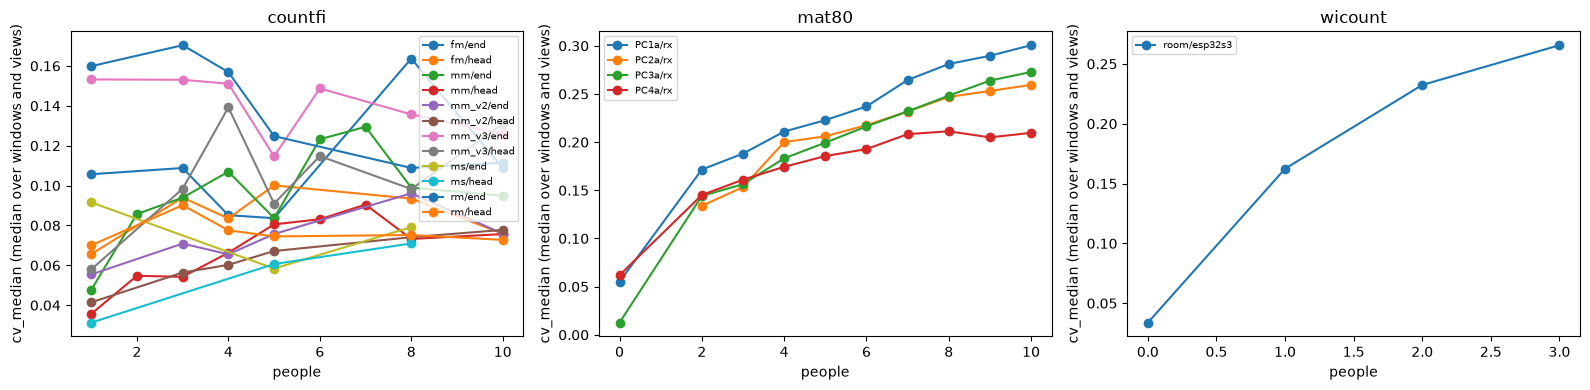

dataset  setup  receiver
countfi  fm     end         0.200000
                head        0.142857
         mm     end         0.600000
                head        0.733333
         mm_v2  end         0.885714
                head        1.000000
         mm_v3  end        -0.785714
                head        0.392857
         ms     end        -0.500000
                head        1.000000
         rm     end        -0.885714
                head       -0.085714
mat80    PC1a   rx          1.000000
         PC2a   rx          1.000000
         PC3a   rx          1.000000
         PC4a   rx          0.939394
wicount  room   esp32s3     1.000000
Name: spearman_cv_vs_count, dtype: float64

In [7]:
# 8. Sanity check: does the main count cue still rise with people after the 20 MHz cut?
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (dataset, g) in zip(axes, feat.groupby("dataset")):
    per_rec = g.groupby(["setup", "receiver", "count"])["cv_median"].median().reset_index()
    for (setup, receiver), h in per_rec.groupby(["setup", "receiver"]):
        h = h.sort_values("count")
        ax.plot(h["count"], h["cv_median"], marker="o", label=f"{setup}/{receiver}")
    ax.set_title(dataset)
    ax.set_xlabel("people")
    ax.set_ylabel("cv_median (median over windows and views)")
    ax.legend(fontsize=7)
fig.tight_layout()

fig_dir = os.path.join(OUT_ROOT, "figures")
os.makedirs(fig_dir, exist_ok=True)
fig.savefig(os.path.join(fig_dir, "cv_median_vs_count.png"), dpi=120)
plt.show()

# Spearman rank correlation of cv_median with count, per setup (80 MHz audit had 0.83-1.0)
corr = (feat.groupby(["dataset", "setup", "receiver", "count"])["cv_median"].median()
        .reset_index().groupby(["dataset", "setup", "receiver"])
        .apply(lambda h: h["cv_median"].corr(h["count"], method="spearman")))
corr.rename("spearman_cv_vs_count")

In [8]:
# 9. Done
print("Phase 1 finished. Output in", OUT_ROOT)
print("Next: open phase2_baselines_local.ipynb")

Phase 1 finished. Output in D:/wifi/shared_format
Next: open phase2_baselines_local.ipynb
